# 03: Analysis

Reads the curated outputs from `02_preprocessing.ipynb` and builds the hourly
JFK demand table this project's analysis is built on: flight arrivals joined
against yellow taxi and rideshare pickup volume.

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import pandas as pd

spark = (
    SparkSession.builder
    .appName("mast30034_project1_analysis")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.session.timeZone", "America/New_York")
    .getOrCreate()
)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/08/18 00:24:17 WARN Utils: Your hostname, DESKTOP-G75J20V, resolves to a loopback address: 127.0.1.1; using 172.25.167.45 instead (on interface eth0)
26/08/18 00:24:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/18 00:24:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Build the hourly JFK demand table

The join key is the hour a flight's passengers are expected to reach the taxi/rideshare
curb, not the hour they land. We assume ~1 hour from touchdown to curb (deplaning,
baggage claim, walking to ground transport), so each flight's actual arrival hour is
shifted forward by 1 hour before joining against pickup demand. This is a simplifying
assumption, stated here so it can be cited in the report.

In [3]:
bts = pd.read_parquet("../data/curated/bts_jfk_arrivals.parquet")

# ArrTime is stored as HHMM (e.g. 1435.0 = 2:35pm local). Combine with FlightDate
# to get an actual arrival timestamp; a handful of rows have malformed times
# (e.g. BTS's "2400" midnight convention) and fail to parse.
arr_time_str = bts["ArrTime"].fillna(0).astype(int).astype(str).str.zfill(4)
bts["arrival_datetime"] = pd.to_datetime(
    bts["FlightDate"] + " " + arr_time_str.str[:2] + ":" + arr_time_str.str[2:],
    errors="coerce",
)

n_before = len(bts)
bts = bts.dropna(subset=["arrival_datetime"])
print(f"BTS JFK arrivals before/after dropping malformed times: {n_before:,} -> {len(bts):,}")

BTS JFK arrivals before/after dropping malformed times: 50,586 -> 50,553


In [4]:
# Aggregate to hourly flight counts and average delay, then shift forward by 1 hour
# to represent the expected curb-pickup hour (see markdown above).
hourly_flights = (
    bts.groupby(bts["arrival_datetime"].dt.floor("h"))
    .agg(n_flights=("arrival_datetime", "count"), avg_arr_delay_min=("ArrDelayMinutes", "mean"))
    .reset_index(names="arrival_hour")
)
hourly_flights["pickup_hour"] = hourly_flights["arrival_hour"] + pd.Timedelta(hours=1)

print(f"Hourly flight buckets: {len(hourly_flights):,}")
hourly_flights.head()

Hourly flight buckets: 4,125


,arrival_hour,n_flights,avg_arr_delay_min,pickup_hour
0,2025-01-01 00:00:00,4,29.25,2025-01-01 01:00:00
1,2025-01-01 04:00:00,5,0.00,2025-01-01 05:00:00
2,2025-01-01 05:00:00,5,0.00,2025-01-01 06:00:00
3,2025-01-01 06:00:00,6,0.50,2025-01-01 07:00:00
4,2025-01-01 07:00:00,10,5.30,2025-01-01 08:00:00


In [5]:
yellow = spark.read.parquet("../data/curated/yellow_filtered/")
yellow_jfk = yellow.filter(F.col("PULocationID") == 132)

yellow_hourly = (
    yellow_jfk
    .withColumn("pickup_hour", F.date_trunc("hour", F.col("tpep_pickup_datetime")))
    .groupBy("pickup_hour")
    .agg(
        F.count("*").alias("n_yellow_pickups"),
        F.sum(F.when(F.col("RatecodeID") == 2, 1).otherwise(0)).alias("n_flat_fare_pickups"),
        F.avg("fare_amount").alias("avg_yellow_fare"),
        F.avg(F.when(F.col("RatecodeID") == 2, F.col("fare_amount"))).alias("avg_flat_fare"),
        F.avg(F.when(F.col("RatecodeID") == 1, F.col("fare_amount"))).alias("avg_metered_fare"),
    )
    .orderBy("pickup_hour")
)

yellow_hourly_pd = yellow_hourly.toPandas()
print(f"Hourly yellow taxi JFK buckets: {len(yellow_hourly_pd):,}")

/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Hourly yellow taxi JFK buckets: 4,337


/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [6]:
hvfhv = spark.read.parquet("../data/curated/hvfhv_filtered/")
hvfhv_jfk = hvfhv.filter(F.col("PULocationID") == 132)

hvfhv_hourly = (
    hvfhv_jfk
    .withColumn("pickup_hour", F.date_trunc("hour", F.col("pickup_datetime")))
    .groupBy("pickup_hour")
    .agg(
        F.count("*").alias("n_hvfhv_pickups"),
        F.avg("base_passenger_fare").alias("avg_hvfhv_fare"),
    )
    .orderBy("pickup_hour")
)

hvfhv_hourly_pd = hvfhv_hourly.toPandas()
print(f"Hourly HVFHV JFK buckets: {len(hvfhv_hourly_pd):,}")

/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Hourly HVFHV JFK buckets: 4,343


/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [ ]:
# Join on pickup_hour
jfk_hourly = (
    hourly_flights[["pickup_hour", "n_flights", "avg_arr_delay_min"]]
    .merge(yellow_hourly_pd, on="pickup_hour", how="left")
    .merge(hvfhv_hourly_pd, on="pickup_hour", how="left")
)

# The +1 hour shift can push the last hour of June past the taxi/HVFHV data's
# cutoff (2025-06-30 23:59:59), landing on 2025-07-01 00:00 with no matching
# pickup data at all. 
n_before = len(jfk_hourly)
jfk_hourly = jfk_hourly[jfk_hourly["pickup_hour"] < "2025-07-01"]
print(f"Dropped {n_before - len(jfk_hourly)} row(s) past the taxi data's date window")

jfk_hourly[["n_yellow_pickups", "n_flat_fare_pickups", "n_hvfhv_pickups"]] = (
    jfk_hourly[["n_yellow_pickups", "n_flat_fare_pickups", "n_hvfhv_pickups"]].fillna(0)
)

print(f"Joined hourly JFK demand table: {len(jfk_hourly):,} rows")
jfk_hourly.head()

Dropped 1 row(s) past the taxi data's date window
Joined hourly JFK demand table: 4,124 rows


,pickup_hour,n_flights,avg_arr_delay_min,n_yellow_pickups,n_flat_fare_pickups,avg_yellow_fare,avg_flat_fare,avg_metered_fare,n_hvfhv_pickups,avg_hvfhv_fare
0,2025-01-01 01:00:00,4,29.25,59.0,13.0,51.700000,70.0,45.302273,151.0,58.856954
1,2025-01-01 05:00:00,5,0.00,77.0,18.0,50.358442,70.0,43.262500,169.0,51.538225
2,2025-01-01 06:00:00,5,0.00,141.0,47.0,55.039645,70.0,42.601220,262.0,58.509885
3,2025-01-01 07:00:00,6,0.50,112.0,50.0,60.086607,70.0,50.129310,295.0,61.769627
4,2025-01-01 08:00:00,10,5.30,89.0,37.0,56.960674,70.0,47.590000,215.0,59.938698


In [8]:
jfk_hourly.to_parquet("../data/curated/jfk_hourly_demand.parquet", index=False)
print("Saved joined hourly JFK demand table.")

Saved joined hourly JFK demand table.


## Sanity check



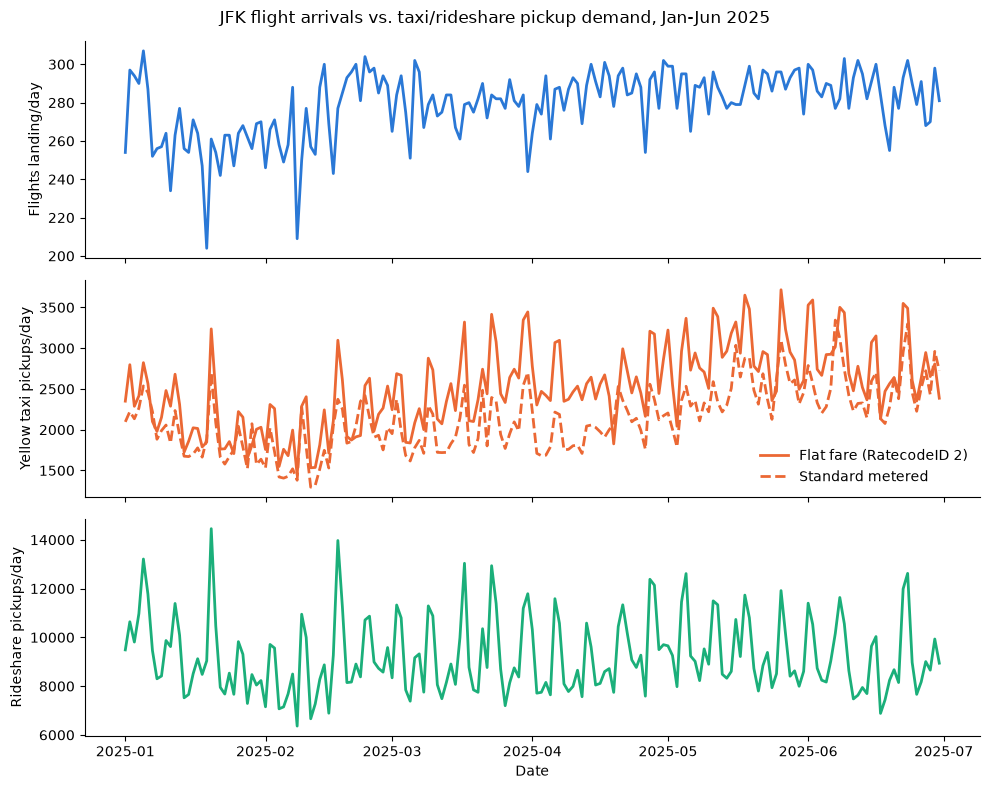

In [9]:
import matplotlib.pyplot as plt

daily = jfk_hourly.set_index("pickup_hour").resample("D").sum(numeric_only=True)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.suptitle("JFK flight arrivals vs. taxi/rideshare pickup demand, Jan-Jun 2025")

axes[0].plot(daily.index, daily["n_flights"], color="#2a78d6", linewidth=2)
axes[0].set_ylabel("Flights landing/day")

axes[1].plot(
    daily.index, daily["n_flat_fare_pickups"],
    color="#eb6834", linewidth=2, label="Flat fare (RatecodeID 2)",
)
axes[1].plot(
    daily.index, daily["n_yellow_pickups"] - daily["n_flat_fare_pickups"],
    color="#eb6834", linewidth=2, linestyle="--", label="Standard metered",
)
axes[1].set_ylabel("Yellow taxi pickups/day")
axes[1].legend(frameon=False)

axes[2].plot(daily.index, daily["n_hvfhv_pickups"], color="#1baf7a", linewidth=2)
axes[2].set_ylabel("Rideshare pickups/day")
axes[2].set_xlabel("Date")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("../plots/jfk_hourly_sanity_check.png", dpi=150)
plt.show()

## Does the flat fare actually stay flat?

 a
true flat fare should have very little variance, regardless of demand conditions.


In [10]:
def fare_stats(sdf, fare_col):
    """
    Compute full-distribution fare statistics for a Spark DataFrame column: mean,
    standard deviation, coefficient of variation (std / mean, a scale-free measure
    of price variability), and key percentiles.
    """
    row = sdf.select(
        F.mean(fare_col).alias("mean"),
        F.stddev(fare_col).alias("std"),
        F.min(fare_col).alias("min"),
        F.max(fare_col).alias("max"),
        F.count(fare_col).alias("n"),
    ).first()

    p25, median, p75 = sdf.approxQuantile(fare_col, [0.25, 0.5, 0.75], 0.01)

    return {
        "n": row["n"],
        "mean": row["mean"],
        "std": row["std"],
        "cv": row["std"] / row["mean"],
        "min": row["min"],
        "p25": p25,
        "median": median,
        "p75": p75,
        "max": row["max"],
    }


yellow_flat = yellow_jfk.filter(F.col("RatecodeID") == 2)
yellow_standard = yellow_jfk.filter(F.col("RatecodeID") == 1)

fare_comparison = pd.DataFrame([
    {"group": "Yellow taxi - JFK flat fare", **fare_stats(yellow_flat, "fare_amount")},
    {"group": "Yellow taxi - standard metered", **fare_stats(yellow_standard, "fare_amount")},
    {"group": "Rideshare (HVFHV)", **fare_stats(hvfhv_jfk, "base_passenger_fare")},
])
fare_comparison

,group,n,mean,std,cv,min,p25,median,p75,max
0,Yellow taxi - JFK flat fare,457903,70.001113,0.104498,0.001493,63.06,70.00,70.00,70.00,86.69
1,Yellow taxi - standard metered,363899,49.556760,23.689641,0.478030,0.80,31.00,45.00,65.30,293.50
2,Rideshare (HVFHV),1688161,61.502128,32.374673,0.526399,0.09,40.64,58.23,76.19,700.00


/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/micha/mast30034-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


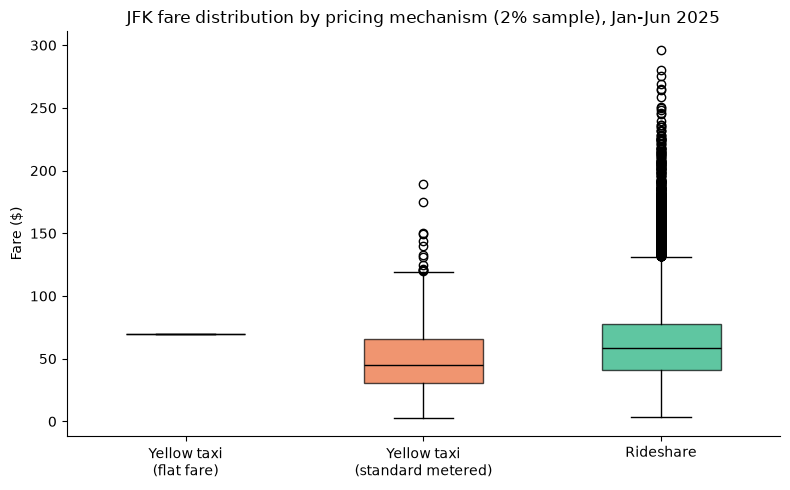

In [ ]:
# 2% keeps the plot responsive while still representing hundreds of thousands
# of trips per group.
SAMPLE_FRAC = 0.02

yellow_flat_sample = yellow_flat.select("fare_amount").sample(SAMPLE_FRAC, seed=0).toPandas()["fare_amount"]
yellow_standard_sample = yellow_standard.select("fare_amount").sample(SAMPLE_FRAC, seed=0).toPandas()["fare_amount"]
hvfhv_sample = hvfhv_jfk.select("base_passenger_fare").sample(SAMPLE_FRAC, seed=0).toPandas()["base_passenger_fare"]

fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [yellow_flat_sample, yellow_standard_sample, hvfhv_sample],
    tick_labels=["Yellow taxi\n(flat fare)", "Yellow taxi\n(standard metered)", "Rideshare"],
    patch_artist=True,
    widths=0.5,
)
for patch, color in zip(box["boxes"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for line in box["medians"]:
    line.set_color("black")

ax.set_ylabel("Fare ($)")
ax.set_title("JFK fare distribution by pricing mechanism (2% sample), Jan-Jun 2025")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../plots/jfk_fare_variance_boxplot.png", dpi=150)
plt.show()

## Does price respond to flight-driven demand?
 if the mechanism is real, hourly rideshare fare should
correlate with flight arrival volume (a proxy for curb demand), while the flat fare
should show close to no correlation at all.

In [12]:
demand_price_corr = jfk_hourly[["n_flights", "avg_flat_fare", "avg_metered_fare", "avg_hvfhv_fare"]].corr()
demand_price_corr["n_flights"]

n_flights           1.000000
avg_flat_fare       0.022860
avg_metered_fare    0.385425
avg_hvfhv_fare      0.535966
Name: n_flights, dtype: float64

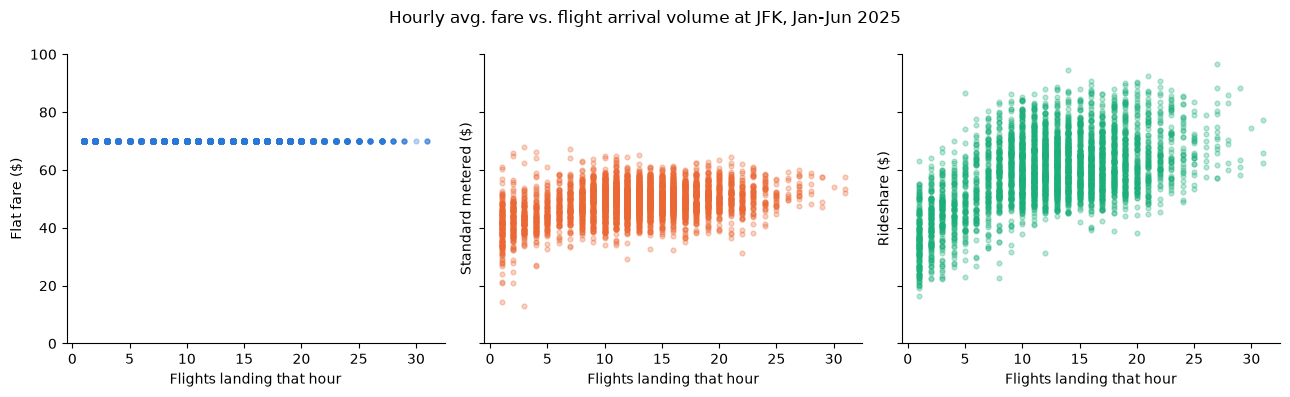

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

series = [
    ("avg_flat_fare", "Flat fare ($)", "#2a78d6"),
    ("avg_metered_fare", "Standard metered ($)", "#eb6834"),
    ("avg_hvfhv_fare", "Rideshare ($)", "#1baf7a"),
]
for ax, (col, ylabel, color) in zip(axes, series):
    ax.scatter(jfk_hourly["n_flights"], jfk_hourly[col], color=color, alpha=0.3, s=12)
    ax.set_xlabel("Flights landing that hour")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)

# Shared y-axis across all three panels: the point of this figure is comparing
# how much each price moves, so an auto-zoomed axis on the near-constant flat
# fare would visually exaggerate noise that isn't really there.
axes[0].set_ylim(0, 100)

fig.suptitle("Hourly avg. fare vs. flight arrival volume at JFK, Jan-Jun 2025")
plt.tight_layout()
plt.savefig("../plots/jfk_demand_vs_price.png", dpi=150)
plt.show()